#LABSHEET 6

##Step 1: Import the required Python libraries and load a real-world image such as a medical image, satellite image, or natural scene.


Saving download (4).png to download (4).png
Image loaded: download (4).png


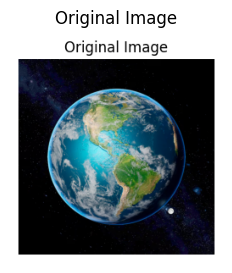

Name:Aman Malik
CU24250099


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()
filename = next(iter(uploaded))
image = cv2.imread(filename)

print("Image loaded:", filename)

plt.figure(figsize=(4, 3))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")
plt.show()

print("Name:Aman Malik")
print("CU24250099")

##Step 2: Convert the image into grayscale and perform basic preprocessing to reduce noise using Gaussian Blur


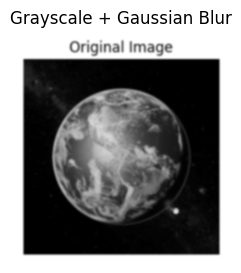

Name:Aman Malik
CU24250099


In [2]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

plt.figure(figsize=(4, 3))
plt.imshow(blurred, cmap="gray")
plt.title("Grayscale + Gaussian Blur")
plt.axis("off")
plt.show()

print("Name:Aman Malik")
print("CU24250099")

##Step 3 Apply Global Thresholding to separate foreground objects from the background and observe the segmentation results.



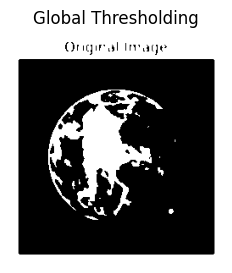

Name:Aman Malik
CU24250099


In [3]:
_, global_thresh = cv2.threshold(
    blurred, 127, 255, cv2.THRESH_BINARY
)

plt.figure(figsize=(4, 3))
plt.imshow(global_thresh, cmap="gray")
plt.title("Global Thresholding")
plt.axis("off")
plt.show()

print("Name:Aman Malik")
print("CU24250099")

##Step 4 Implement Otsu's Thresholding to automatically determine the optimal threshold value and compare it with global thresholding.


Otsu Threshold: 116.0


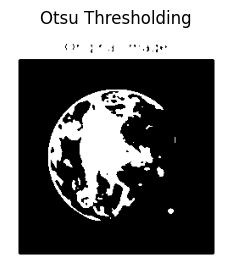

Name:Aman Malik
CU24250099


In [4]:
otsu_value, otsu_thresh = cv2.threshold(
    blurred, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("Otsu Threshold:", otsu_value)

plt.figure(figsize=(4, 3))
plt.imshow(otsu_thresh, cmap="gray")
plt.title("Otsu Thresholding")
plt.axis("off")
plt.show()

print("Name:Aman Malik")
print("CU24250099")

##Step 5 Apply Adaptive Thresholding to segment images with uneven illumination conditions.


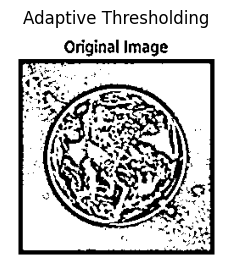

Name:Aman Malik
CU24250099


In [5]:
adaptive = cv2.adaptiveThreshold(
    blurred, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    11, 2
)

plt.figure(figsize=(4, 3))
plt.imshow(adaptive, cmap="gray")
plt.title("Adaptive Thresholding")
plt.axis("off")
plt.show()

print("Name:Aman Malik")
print("CU24250099")

## Step 6 Implement the Watershed Segmentation algorithm to separate overlapping or touching objects within the image.



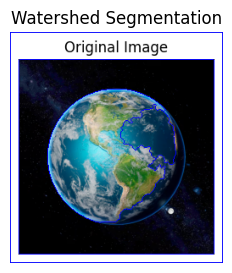

Name:Aman Malik
CU24250099


In [6]:
# Question 6: Implement Watershed Segmentation

_, binary = cv2.threshold(
    blurred, 0, 255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

kernel = np.ones((3, 3), np.uint8)

opening = cv2.morphologyEx(
    binary, cv2.MORPH_OPEN, kernel, iterations=2
)

sure_bg = cv2.dilate(opening, kernel, iterations=3)

dist = cv2.distanceTransform(
    opening, cv2.DIST_L2, 5
)

_, sure_fg = cv2.threshold(
    dist, 0.5 * dist.max(), 255, 0
)

sure_fg = np.uint8(sure_fg)
unknown = cv2.subtract(sure_bg, sure_fg)

_, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0

result = image.copy()
markers = cv2.watershed(result, markers)

result[markers == -1] = [255, 0, 0]

plt.figure(figsize=(4, 3))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Watershed Segmentation")
plt.axis("off")
plt.show()

print("Name:Aman Malik")
print("CU24250099")

## Step 7 Apply K-Means Clustering for color-based image segmentation by grouping pixels into distinct clusters.


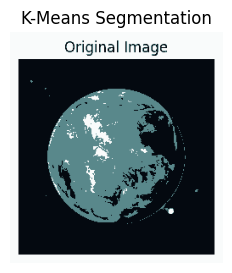

Name:Aman Malik
CU24250099


In [7]:
img_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
pixels = np.float32(img_rgb.reshape(-1, 3))

criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)

_, labels, centers = cv2.kmeans(
    pixels, 3, None, criteria, 10,
    cv2.KMEANS_RANDOM_CENTERS
)

centers = np.uint8(centers)
segmented = centers[labels.flatten()].reshape(img_rgb.shape)

plt.figure(figsize=(4, 3))
plt.imshow(segmented)
plt.title("K-Means Segmentation")
plt.axis("off")
plt.show()

print("Name:Aman Malik")
print("CU24250099")

## Step 8 Compare the segmentation outputs obtained from different techniques based on object boundaries, accuracy, and computational efficiency.


In [8]:
print("Segmentation Comparison")
print("-----------------------")
print("Global Threshold : Fast, works with uniform illumination.")
print("Otsu             : Automatic threshold selection, fast.")
print("Adaptive         : Good for uneven illumination.")
print("Watershed        : Good for touching objects.")
print("K-Means          : Good for color-based segmentation.")

print("\nOverall, the best technique depends on the image characteristics.")

print("Name:Aman Malik")
print("CU24250099")

Segmentation Comparison
-----------------------
Global Threshold : Fast, works with uniform illumination.
Otsu             : Automatic threshold selection, fast.
Adaptive         : Good for uneven illumination.
Watershed        : Good for touching objects.
K-Means          : Good for color-based segmentation.

Overall, the best technique depends on the image characteristics.
Name:Aman Malik
CU24250099


##Step 9 Visualize and analyze the segmented images to identify the most suitable technique for the selected dataset.


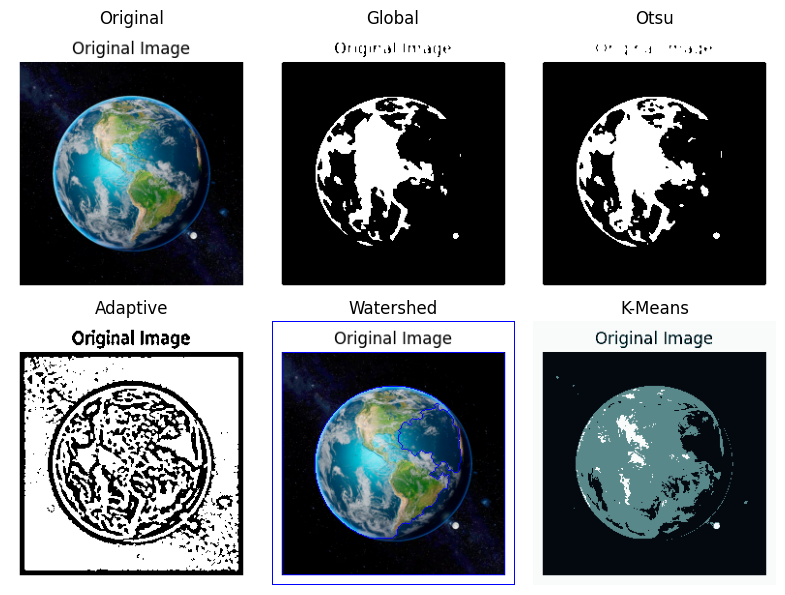

Most suitable technique depends on the image.
Watershed is useful for touching objects.
K-Means is useful for color-based segmentation.
Name:Aman Malik
CU24250099


In [9]:
plt.figure(figsize=(8, 6))

plt.subplot(2, 3, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(global_thresh, cmap="gray")
plt.title("Global")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(otsu_thresh, cmap="gray")
plt.title("Otsu")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(adaptive, cmap="gray")
plt.title("Adaptive")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Watershed")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(segmented)
plt.title("K-Means")
plt.axis("off")

plt.tight_layout()
plt.show()
plt.close()

print("Most suitable technique depends on the image.")
print("Watershed is useful for touching objects.")
print("K-Means is useful for color-based segmentation.")

print("Name:Aman Malik")
print("CU24250099")

##Step 10 Summarize the observations and discuss the role of image segmentation in advanced computer vision applications.


In [10]:
print("Observations and Conclusion")
print("---------------------------")
print("1. Segmentation separates an image into meaningful regions.")
print("2. Global and Otsu thresholding are simple and fast.")
print("3. Adaptive thresholding handles uneven illumination.")
print("4. Watershed separates touching objects.")
print("5. K-Means is useful for color-based segmentation.")
print("6. Image segmentation is important in medical imaging,")
print("   satellite analysis, object detection and autonomous systems.")

print("Name:Aman Malik")
print("CU24250099")

Observations and Conclusion
---------------------------
1. Segmentation separates an image into meaningful regions.
2. Global and Otsu thresholding are simple and fast.
3. Adaptive thresholding handles uneven illumination.
4. Watershed separates touching objects.
5. K-Means is useful for color-based segmentation.
6. Image segmentation is important in medical imaging,
   satellite analysis, object detection and autonomous systems.
Name:Aman Malik
CU24250099
